In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import data_utils_all as du

In [2]:
# see the data_utils_all.py file 
# load_clean function loads and does basic cleaning
# all cleaning options can be turned on and off in the function

df = du.load_clean("../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt", trim=False, continuous=False, transfix=False)

df.head()

../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 69125 rows


,Timer(ms),Loc(m),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
0,45476731.0,3767.52,426290.475,7414101.054,107.049,1.6195,-1.7959,13.5969,0.42274,0.24780,9.84059,-0.00239,0.00271,-0.00435,0.87092,0.85334,0.0,0.0,0.0,0.126
1,45476733.5,3767.52,426290.475,7414101.054,107.049,1.6197,-1.7954,13.5971,0.37197,0.22563,9.83939,-0.00394,0.00529,-0.00295,0.87092,0.85334,0.0,0.0,0.0,0.126
2,45476728.5,3767.52,426290.475,7414101.054,107.048,1.6192,-1.7961,13.5968,0.39457,0.25581,9.83537,-0.00354,0.00251,-0.00404,0.87092,0.85334,0.0,0.0,0.0,0.126
3,45476736.0,3767.52,426290.475,7414101.054,107.049,1.6196,-1.7955,13.5979,0.41483,0.22451,9.83531,-0.00540,0.00077,0.00153,0.87092,0.85334,0.0,0.0,0.0,0.126
4,45476726.0,3767.52,426290.475,7414101.054,107.048,1.6190,-1.7962,13.5968,0.39042,0.27895,9.82614,-0.00743,-0.00130,-0.00236,0.87092,0.85334,0.0,0.0,0.0,0.126


In [3]:
# trimming the ends of the data 
# sensor and timestamps are off and unreliable here, so they need to go
trimmed = du.trim_ends(df)

print("Kept Loc:", round(trimmed["Loc(m)"].min()), "-", round(trimmed["Loc(m)"].max()))
print("Rows:", len(df), "->", len(trimmed))

Kept Loc: 3851 - 6867
Rows: 69125 -> 56873


In [4]:
def fix_transitions(dfcol, threshold=0.05, settle=3, tol=0.02):
    """
    Label a noisy signal with clean whole numbers (baseline 0).
    Rise: whole ramp gets the level it settles on. Drop: labelled 0.
    Stable rows: rounded.

    threshold: row-to-row change that counts as movement
    settle:    still rows needed to count as settled
    tol:       max distance from a whole number to count as on it
    """
    v = dfcol.to_numpy(dtype=float)
    out = np.rint(v).astype(int)                 # default: rounded values
    diff = np.diff(v, prepend=v[0])              # change from previous row
    changed = np.abs(diff) > threshold           # True where the signal moved

    start, direction, quiet = None, 0, 0         # transition start, +1 rise / -1 drop, still rows
    for i in range(len(v)):
        quiet = 0 if changed[i] else quiet + 1

        if changed[i] and start is None:         # a jump begins a transition
            start = i
            direction = 1 if diff[i] > 0 else -1

        # settled: no movement for `settle` rows AND on a whole number
        if start is not None and quiet >= settle and abs(v[i] - round(v[i])) <= tol:
            out[start:i + 1] = round(v[i]) if direction > 0 else 0
            start = None

    if start is not None:                        # data ended mid-transition
        out[start:] = max(round(v[-1]), 0) if direction > 0 else 0

    return pd.Series(out, index=dfcol.index)

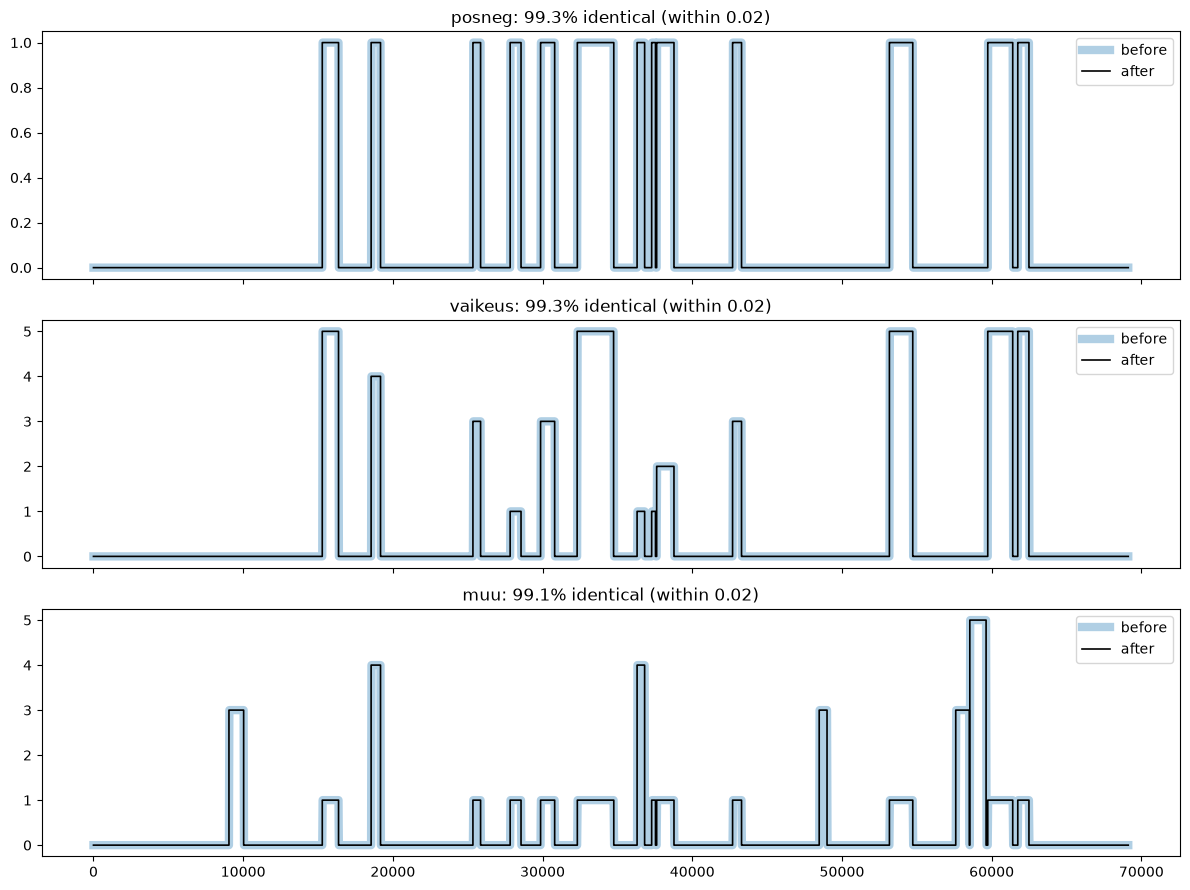

In [5]:
cols_to_fix = ['posneg', 'vaikeus', 'muu']
df_cleaned = df.copy()

for col in cols_to_fix:
    df_cleaned[col] = fix_transitions(df_cleaned[col], threshold=0.05, settle=3, tol=0.02)


def plot_before_after(df_before, df_after, columns, tol=0.02):
    fig, axes = plt.subplots(len(columns), 1, figsize=(12, 3 * len(columns)), sharex=True, squeeze=False)
    for ax, col in zip(axes[:, 0], columns):
        b, a = df_before[col], df_after[col]
        same = (b - a).abs() <= tol

        # before: thick and light underneath, after: thin and dark on top.
        # Where they overlap, the thin line sits inside the thick one.
        ax.plot(b.index, b, color="tab:blue", linewidth=6, alpha=0.35, label="before")
        ax.step(a.index, a, where="post", color="black", linewidth=1.2, label="after")

        # red dots mark rows where they differ by more than tol -> uncomment to see where the function has fixed stuff
        # important that the red dots only show up in up/down slopes -> these are what needs to be changed
        # ax.scatter(b.index[~same], b[~same], color="red", s=18, zorder=3, label="differs")

        ax.set_title(f"{col}: {same.mean():.1%} identical (within {tol})")
        ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_before_after(df, df_cleaned, cols_to_fix)

In [6]:
# this looks good, applying ficit to the actual dataset
# not really needed for all the columns since some are getting dropped with no use anyway, but may as well 


for col in cols_to_fix:
    df[col] = fix_transitions(df[col], threshold=0.05, settle=3, tol=0.02, )

In [7]:
# creating frostbump column that is just does 0/1
# this makes muu redundant, as well as posneg & vaikeus
 
df["Frostbumps"] = (
    (df["muu"] == 1) |
    (df["muu"] == 2)
).astype(int)

df["Frostbumps"]

0        0
1        0
2        0
3        0
4        0
        ..
69120    0
69121    0
69122    0
69123    0
69124    0
Name: Frostbumps, Length: 69125, dtype: int64

In [8]:
# UNCOMMENT ONE OF THE TWO OPERATIONS!!!

# dropping any data leaky columns

'''
df = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)"], axis=1)
'''

# OR
# creating delta between the two RBCSVs, then dropping them both 

'''

df["RBCSV_delta"] = df["RBCSV_80(cf)"] - df["RBCSV_60(cf)"]
df = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)", "RBCSV_80(cf)"], axis=1)

'''



'\n\ndf["RBCSV_delta"] = df["RBCSV_80(cf)"] - df["RBCSV_60(cf)"]\ndf = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)", "RBCSV_80(cf)"], axis=1)\n\n'